<a href="https://colab.research.google.com/github/justleein2/MachineLearning/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
!pip -q install hdbscan

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import hdbscan

Task 1: Print the relevant data using shape, names, and head. Then standardize the 13 Features for visual comparison using a boxplot.

Dataset Shape: (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']

Class Distribution:
 0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



 Statistics:
           alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   


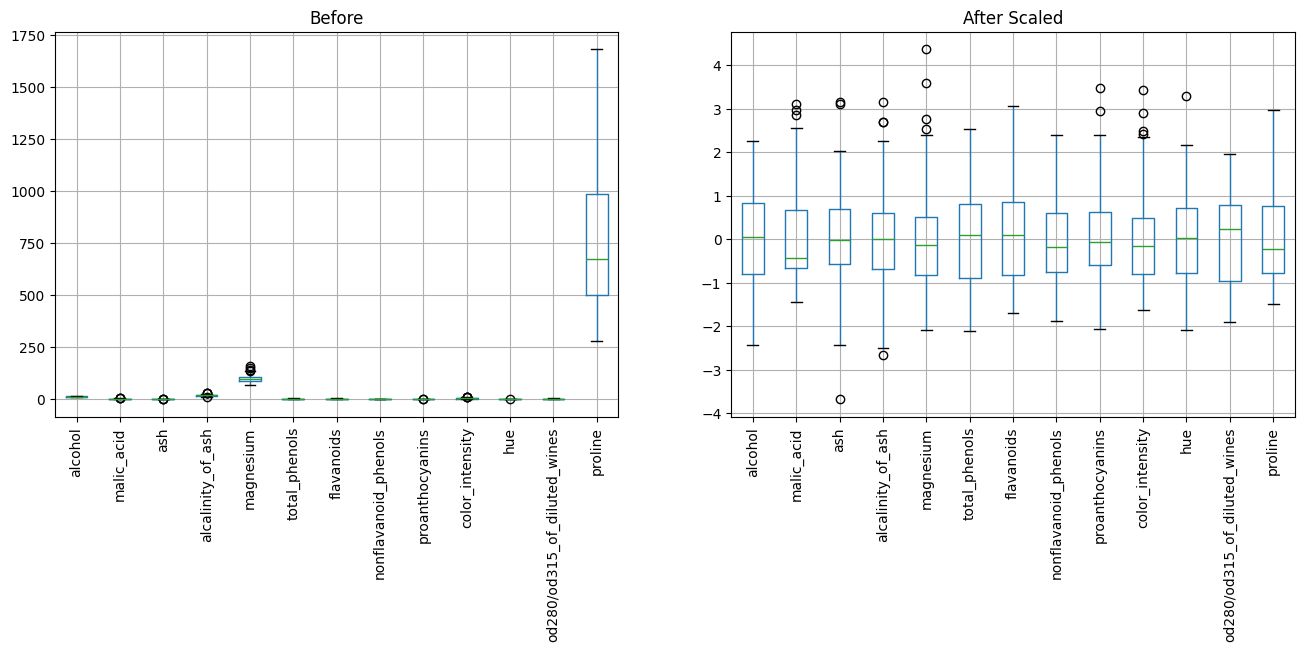

In [32]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names

df = pd.DataFrame(X, columns=feature_names)

print("Dataset Shape:", X.shape)
print("Target Classes:", wine.target_names)
print("\nClass Distribution:\n", pd.Series(y).value_counts().sort_index())
display(df.head())
print("\n Statistics:\n", df.describe())
print("\nMissing:\n", df.isnull().sum())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=feature_names)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df.boxplot(ax=axes[0], rot=90)
axes[0].set_title("Before")
df_scaled.boxplot(ax=axes[1], rot=90)
axes[1].set_title("After Scaled")
plt.show()

Task 2:
Iterates k from 1 to 10 for fitting in both curves.
Use the Elbow Curve and Silloutte Scores to find the optimal value of k.

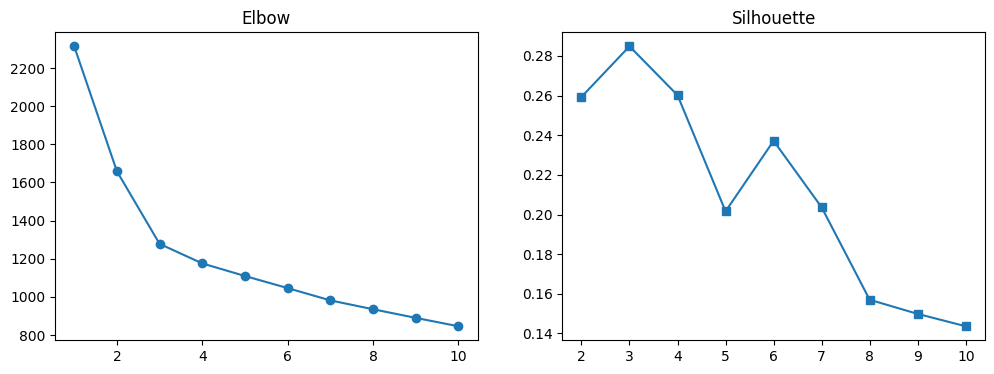


Best k by elbow: 3
Best k by silhouette: 3


In [42]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia, sil = [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    if k >= 2:
        sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 11), inertia, "o-"); ax[0].set_title("Elbow")
ax[1].plot(range(2, 11), sil, "s-"); ax[1].set_title("Silhouette")
plt.show()

print("\nBest k by elbow: 3")
print("Best k by silhouette:", 2 + int(np.argmax(sil)))


Task 3: Use PCA to evaluate the variance in the data and reduce the 13 features to two primary ones. From the PCA, create a fitted KMeans to be projected. Using a scatter plot, the data is separated into clusters.

Explained variance ratio: [0.362 0.192] | cumulative: 0.554


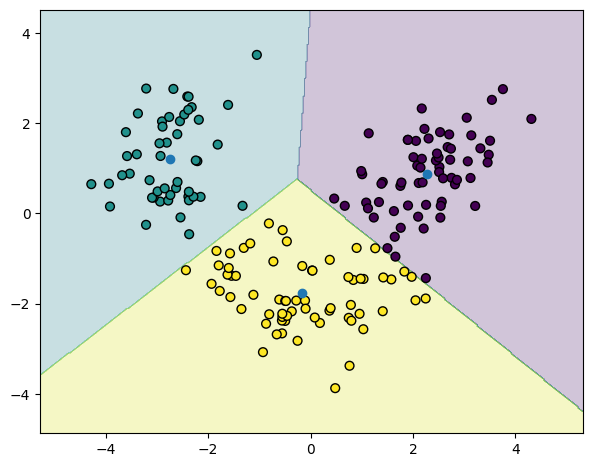

In [19]:
from sklearn.decomposition import PCA


pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| cumulative:", pca.explained_variance_ratio_.sum().round(3))

km2 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_pca)
labels2 = km2.labels_

xx, yy = np.meshgrid(np.linspace(X_pca[:,0].min()-1, X_pca[:,0].max()+1, 400),
                     np.linspace(X_pca[:,1].min()-1, X_pca[:,1].max()+1, 400))
Z = km2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 5.5))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels2, cmap="viridis", edgecolor="k", s=40)
plt.scatter(km2.cluster_centers_[:,0], km2.cluster_centers_[:,1])


Task 4: Create a heatmap using a fitted KMeans model to find the distances to centroids.

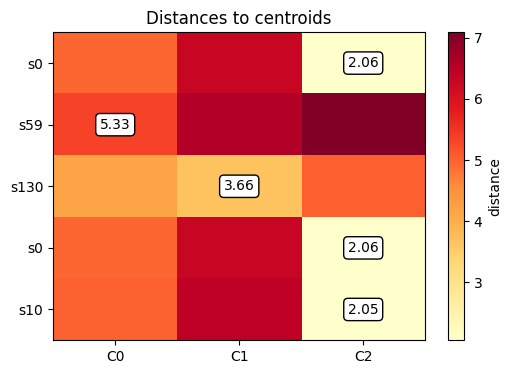

In [20]:
from scipy.spatial.distance import cdist

km_full = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)

sample_idx = [np.where(y == c)[0][0] for c in range(3)] + [0, 10]
D = cdist(X_scaled[sample_idx], km_full.cluster_centers_)

plt.figure(figsize=(6, 4))
plt.imshow(D, cmap="YlOrRd", aspect="auto")
plt.colorbar(label="distance")
for r in range(D.shape[0]):
    c = D[r].argmin()
    plt.text(c, r, f"{D[r,c]:.2f}", ha="center", va="center",
             bbox=dict(boxstyle="round", fc="white"))
plt.xticks(range(3), [f"C{i}" for i in range(3)])
plt.yticks(range(len(sample_idx)), [f"s{i}" for i in sample_idx])
plt.title("Distances to centroids")
plt.show()

Task 5: Create a DBSCAN model visual that can show noise and clusters separately.

eps=1.5: clusters=0, noise=178
eps=2.0: clusters=5, noise=85


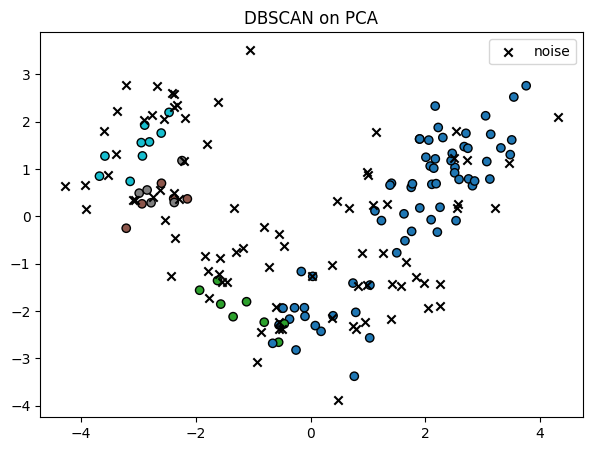

In [21]:
from sklearn.cluster import DBSCAN

for eps in [1.5, 2.0]:
    db = DBSCAN(eps=eps, min_samples=5).fit(X_scaled)
    n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    print(f"eps={eps}: clusters={n_clusters}, noise={(db.labels_==-1).sum()}")

db = DBSCAN(eps=2.0, min_samples=5).fit(X_scaled)
mask = db.labels_ == -1
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[~mask,0], X_pca[~mask,1], c=db.labels_[~mask], cmap="tab10", edgecolor="k")
plt.scatter(X_pca[mask,0], X_pca[mask,1], c="black", marker="x", label="noise")
plt.legend(); plt.title("DBSCAN on PCA"); plt.show()


Task 6: Create an HDBSCAN visual that can distinguise noise and clusters clearly.

HDBSCAN: clusters=2, noise=70


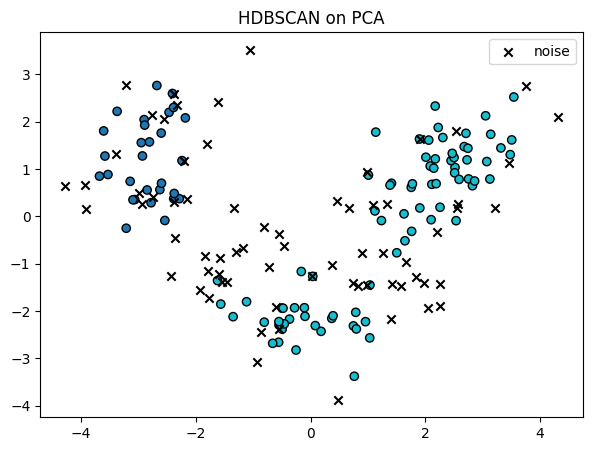

In [22]:
hdb = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=5)
hdb_labels = hdb.fit_predict(X_scaled)
n_clusters = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
print(f"HDBSCAN: clusters={n_clusters}, noise={(hdb_labels==-1).sum()}")

mask = hdb_labels == -1
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[~mask,0], X_pca[~mask,1], c=hdb_labels[~mask], cmap="tab10", edgecolor="k")
plt.scatter(X_pca[mask,0], X_pca[mask,1], c="black", marker="x", label="noise")
plt.legend(); plt.title("HDBSCAN on PCA"); plt.show()

Task 7: Visualizing the Single Linkage Hierarchy Clustering using dendrogram on X_scaled compared to HBDSCAN's condensed tree.

Single-Linkage Clustering Matrix:
   Cluster 1  Cluster 2  Distance  Sample Count
0        9.0       47.0  1.164114           2.0
1      131.0      133.0  1.191602           2.0
2       11.0       12.0  1.209356           2.0
3       15.0       53.0  1.225510           2.0
4       92.0      107.0  1.245388           2.0
5       34.0       37.0  1.268418           2.0
6        0.0       20.0  1.287893           2.0
7       16.0       17.0  1.291794           2.0
8      164.0      172.0  1.300484           2.0
9       56.0      184.0  1.327753           3.0


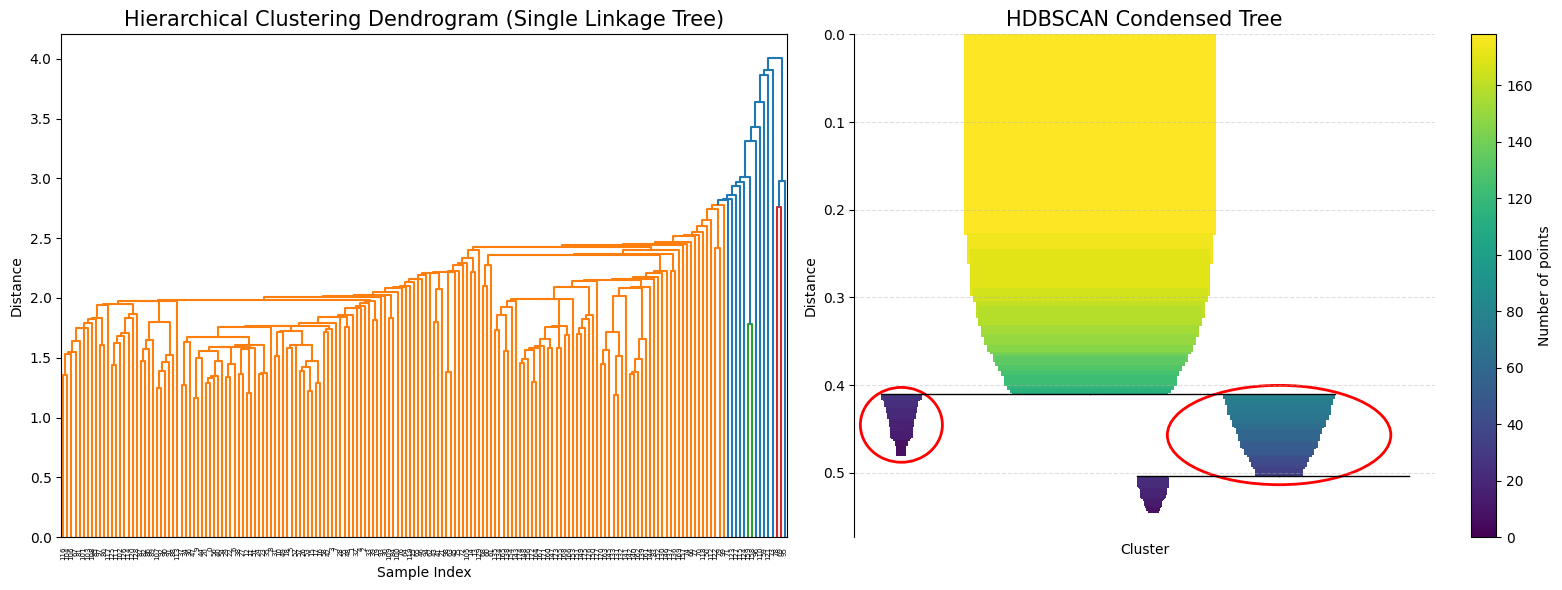

In [41]:
from scipy.cluster.hierarchy import linkage, dendrogram

linked = linkage(X_scaled, method='single')

print("Single-Linkage Clustering Matrix:")
print(pd.DataFrame(linked[:10], columns=['Cluster 1', 'Cluster 2', 'Distance', 'Sample Count']))

fig,ax = plt.subplots(1,2,figsize=(16, 6))

dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=False,
    show_contracted=True,
    ax=ax[0]
)

ax[0].set_title(
    'Hierarchical Clustering Dendrogram (Single Linkage Tree)',
    fontsize=15
)
ax[0].set_xlabel('Sample Index')
ax[0].set_ylabel('Distance')
plt.grid(axis='y', linestyle='--', alpha=0.4)

hdb.condensed_tree_.plot(select_clusters=True, axis=ax[1])
ax[1].set_title(
    'HDBSCAN Condensed Tree',
    fontsize=15
)
ax[1].set_xlabel('Cluster')
ax[1].set_ylabel('Distance')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Task 8: Evaluate K-Means, DBSCAN, and HDBSCAN's performance using a Random Forest classifier and Silhoutte Scores. Then display a bar graph for visualization of the differences.

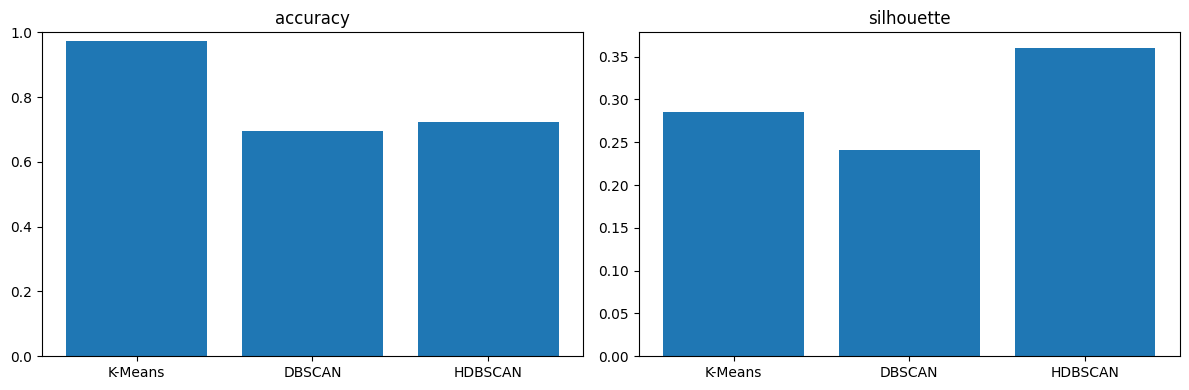

accuracy: {'K-Means': 0.9722222222222222, 'DBSCAN': 0.6944444444444444, 'HDBSCAN': 0.7222222222222222}
silhouette: {'K-Means': np.float64(0.2848589191898987), 'DBSCAN': np.float64(0.24046128028458877), 'HDBSCAN': np.float64(0.3603456273477751)}


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder

km_l = km_full.labels_
db_l = db.labels_
hdb_l = hdb_labels

i_train, i_test  = train_test_split(np.arange(len(y)), test_size=0.2,
                                  stratify=y, random_state=42)

accs, sils = {}, {}
enc = OneHotEncoder(sparse_output=False)
for name, lab in [("K-Means", km_l), ("DBSCAN", db_l), ("HDBSCAN", hdb_l)]:
    F = enc.fit_transform(lab.reshape(-1, 1))

    #RandomForest on clusters
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(F[i_train], y[i_train])

    #accuracy test
    accs[name] = accuracy_score(y[i_test], rf.predict(F[i_test]))

    #silhoutte
    keep = lab != -1
    sils[name] = silhouette_score(X_scaled[keep], lab[keep]) if len(set(lab[keep])) > 1 else np.nan

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(accs.keys(), accs.values());
ax[0].set_title("accuracy");
ax[0].set_ylim(0, 1)
ax[1].bar(sils.keys(), sils.values());
ax[1].set_title("silhouette")
plt.tight_layout();
plt.show()
print("accuracy:", accs)
print("silhouette:", sils)
